In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from skimage import data

I = data.camera()      
M, N = I.shape

def show_row(images, titles, cmap="gray", size=4):
    """Show several images side by side."""
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size))
    for ax, img, t in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(img, cmap=cmap, vmin=0, vmax=255)
        ax.set_title(t); ax.axis("off")
    plt.tight_layout(); plt.show()

def psnr(ref, test):
    """Peak signal-to-noise ratio in dB (higher = closer to ref)."""
    mse = np.mean((ref.astype(np.float64) - test.astype(np.float64)) ** 2)
    return 10 * np.log10(255 ** 2 / mse)

def point_op(img, a=1.0, b=0.0):
    """g = a*f + b, computed in float and clipped to uint8 (from Lab 2)."""
    return np.clip(a * img.astype(np.float64) + b, 0, 255).astype(np.uint8)

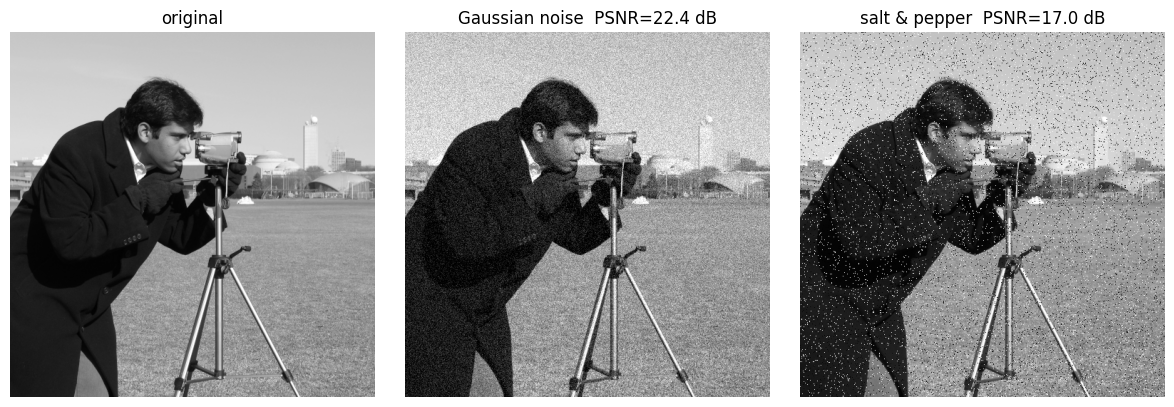

In [ ]:
rng = np.random.default_rng(383)                   

noisy_g = np.clip(I + rng.normal(0, 20, I.shape), 0, 255).astype(np.uint8)

noisy_sp = I.copy()
r = rng.random(I.shape)
noisy_sp[r < 0.03] = 0
noisy_sp[r > 0.97] = 255

show_row([I, noisy_g, noisy_sp],
         ["original",
          f"Gaussian noise  PSNR={psnr(I, noisy_g):.1f} dB",
          f"salt & pepper  PSNR={psnr(I, noisy_sp):.1f} dB"])

### D.2 — four smoothing filters

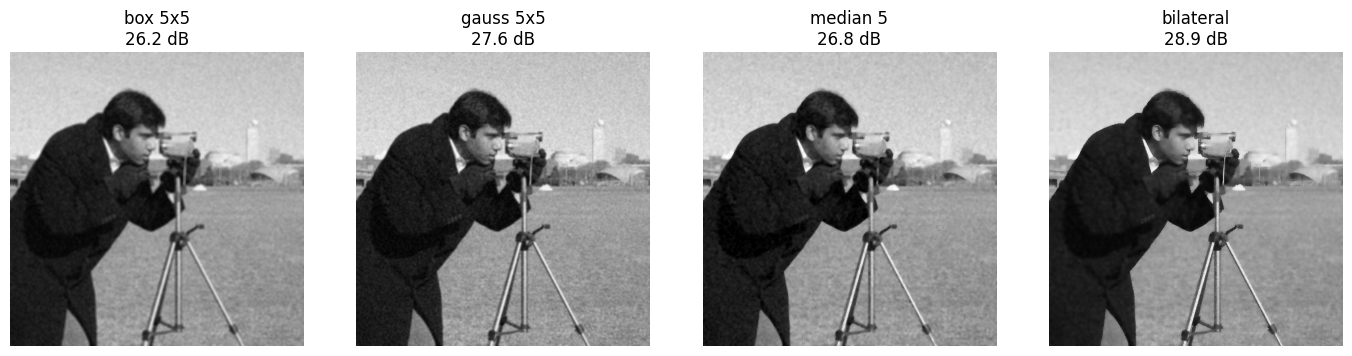

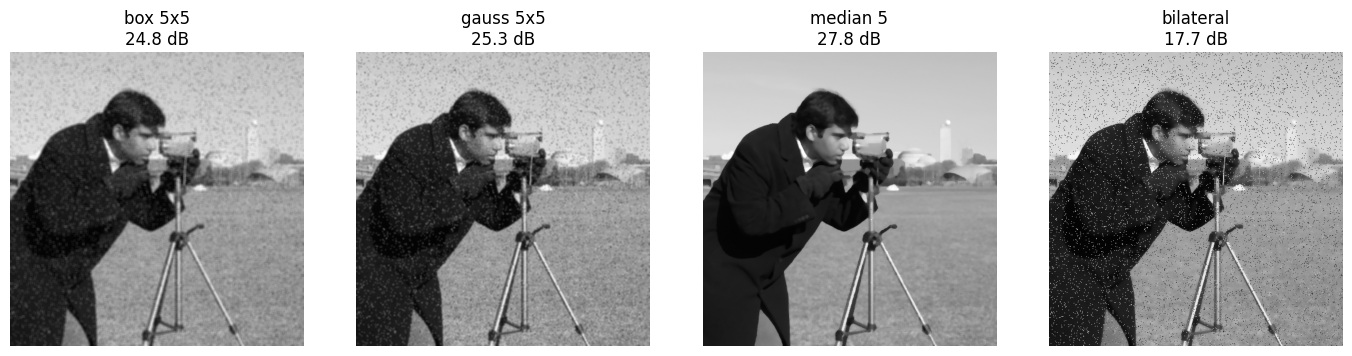

[[  7.  21.  29.  21.   7.]
 [ 21.  59.  83.  59.  21.]
 [ 29.  83. 118.  83.  29.]
 [ 21.  59.  83.  59.  21.]
 [  7.  21.  29.  21.   7.]]
sum = 1.0


In [ ]:
def smooth_all(img):
    return {"box 5x5":    cv2.blur(img, (5, 5)),
            "gauss 5x5":  cv2.GaussianBlur(img, (5, 5), 1.2),
            "median 5":   cv2.medianBlur(img, 5),
            "bilateral":  cv2.bilateralFilter(img, 9, 50, 9)}

for name, noisy in [("Gaussian", noisy_g), ("salt & pepper", noisy_sp)]:
    results = smooth_all(noisy)
    show_row(list(results.values()),
             [f"{k}\n{psnr(I, v):.1f} dB" for k, v in results.items()], size=3.5)

g1 = cv2.getGaussianKernel(5, 1.2)   
G = g1 @ g1.T                     
print((G * 1000).round(0)); print("sum =", G.sum())

In [4]:
g1 = cv2.getGaussianKernel(5, 1.2)
sep = cv2.sepFilter2D(I, -1, g1, g1)
full = cv2.filter2D(I, -1, g1 @ g1.T)
print("max |separable - full 2D| =", np.abs(sep.astype(int) - full.astype(int)).max())

max |separable - full 2D| = 1


In [5]:
rows = {}
for name, noisy in [("Gaussian noise", noisy_g), ("Salt & pepper", noisy_sp)]:
    res = smooth_all(noisy)
    rows[name] = {k: round(psnr(I, v), 2) for k, v in res.items()}
table = pd.DataFrame(rows).T
table.insert(0, "noisy (no filter)", [round(psnr(I, noisy_g), 2), round(psnr(I, noisy_sp), 2)])
table.index.name = "PSNR (dB)"
table

,noisy (no filter),box 5x5,gauss 5x5,median 5,bilateral
PSNR (dB),,,,,
Gaussian noise,22.42,26.18,27.62,26.8,28.93
Salt & pepper,17.02,24.79,25.31,27.8,17.74


PSNR (dB)
Gaussian noise    bilateral
Salt & pepper      median 5
dtype: str


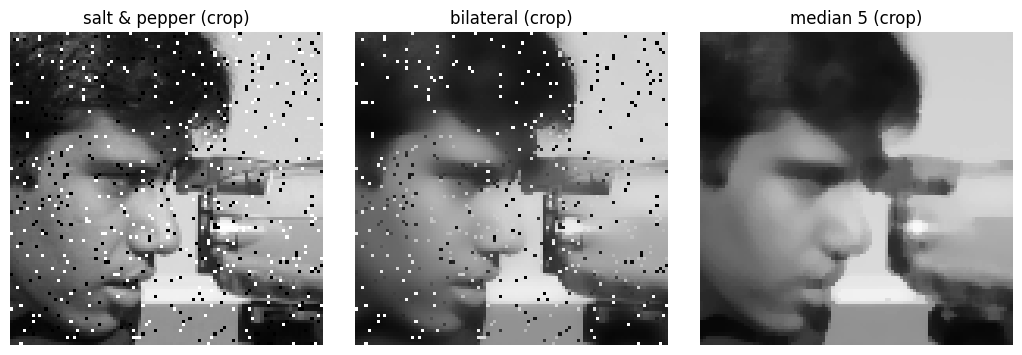

In [ ]:
print(table.drop(columns="noisy (no filter)").idxmax(axis=1))

bil_sp = smooth_all(noisy_sp)["bilateral"]
show_row([noisy_sp[100:200, 200:300], bil_sp[100:200, 200:300],
          smooth_all(noisy_sp)["median 5"][100:200, 200:300]],
         ["salt & pepper (crop)", "bilateral (crop)", "median 5 (crop)"], size=3.5)

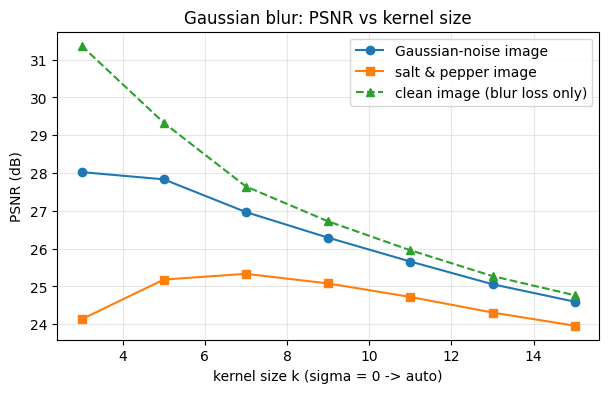

 k  sigma(auto)  PSNR gauss noise  PSNR s&p  PSNR clean
 3          0.8             28.03     24.13       31.37
 5          1.1             27.83     25.18       29.33
 7          1.4             26.97     25.33       27.64
 9          1.7             26.29     25.08       26.72
11          2.0             25.66     24.72       25.96
13          2.3             25.06     24.31       25.27
15          2.6             24.60     23.96       24.77
best k for Gaussian noise: 3


In [ ]:
ks = list(range(3, 16, 2))
p_g  = [psnr(I, cv2.GaussianBlur(noisy_g,  (k, k), 0)) for k in ks]  
p_sp = [psnr(I, cv2.GaussianBlur(noisy_sp, (k, k), 0)) for k in ks]
p_cl = [psnr(I, cv2.GaussianBlur(I,        (k, k), 0)) for k in ks]  
sig  = [0.3 * ((k - 1) * 0.5 - 1) + 0.8 for k in ks]                  
plt.figure(figsize=(7, 4))
plt.plot(ks, p_g,  "o-", label="Gaussian-noise image")
plt.plot(ks, p_sp, "s-", label="salt & pepper image")
plt.plot(ks, p_cl, "^--", label="clean image (blur loss only)")
plt.xlabel("kernel size k (sigma = 0 -> auto)"); plt.ylabel("PSNR (dB)")
plt.title("Gaussian blur: PSNR vs kernel size"); plt.grid(alpha=.3); plt.legend(); plt.show()
print(pd.DataFrame({"k": ks, "sigma(auto)": np.round(sig, 2), "PSNR gauss noise": np.round(p_g, 2),
                    "PSNR s&p": np.round(p_sp, 2), "PSNR clean": np.round(p_cl, 2)}).to_string(index=False))
print("best k for Gaussian noise:", ks[int(np.argmax(p_g))])

In [ ]:
sigma = 1.2
ax = np.arange(-2, 3)
xx, yy = np.meshgrid(ax, ax)
G_mine = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
G_mine /= G_mine.sum()                   
print((G_mine * 1000).round(0)); print("sum =", G_mine.sum())
print("equals G from OpenCV (allclose):", np.allclose(G_mine, G))

[[  7.  21.  29.  21.   7.]
 [ 21.  59.  83.  59.  21.]
 [ 29.  83. 118.  83.  29.]
 [ 21.  59.  83.  59.  21.]
 [  7.  21.  29.  21.   7.]]
sum = 1.0
equals G from OpenCV (allclose): True


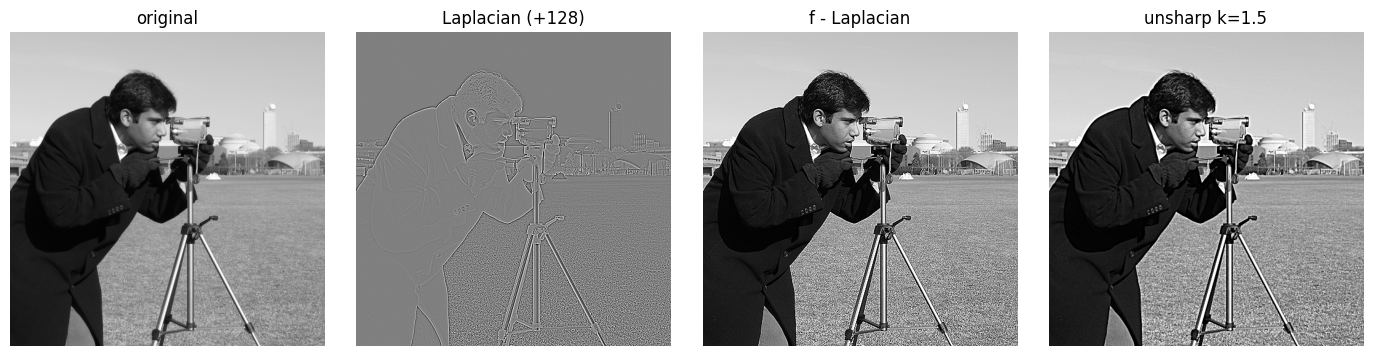

In [ ]:
lap_kernel = np.array([[0, 1, 0],
                       [1, -4, 1],
                       [0, 1, 0]], dtype=np.float64)
L = cv2.filter2D(I.astype(np.float64), -1, lap_kernel)      
sharp_lap = np.clip(I - L, 0, 255).astype(np.uint8)

blur = cv2.GaussianBlur(I, (0, 0), sigmaX=2)
k = 1.5
unsharp = cv2.addWeighted(I, 1 + k, blur, -k, 0)          

L_show = np.clip(L + 128, 0, 255).astype(np.uint8)           
show_row([I, L_show, sharp_lap, unsharp],
         ["original", "Laplacian (+128)", "f - Laplacian", "unsharp k=1.5"], size=3.5)

In [ ]:
K = np.array([[0, -1, 0],
              [-1, 5, -1],
              [0, -1, 0]], dtype=np.float64)
one_kernel = cv2.filter2D(I, -1, K)          
print("identical to sharp_lap:", np.array_equal(one_kernel, sharp_lap))
print("kernel check: identity - laplacian =\n", np.array([[0,0,0],[0,1,0],[0,0,0]]) - lap_kernel)

identical to sharp_lap: True
kernel check: identity - laplacian =
 [[ 0. -1.  0.]
 [-1.  5. -1.]
 [ 0. -1.  0.]]


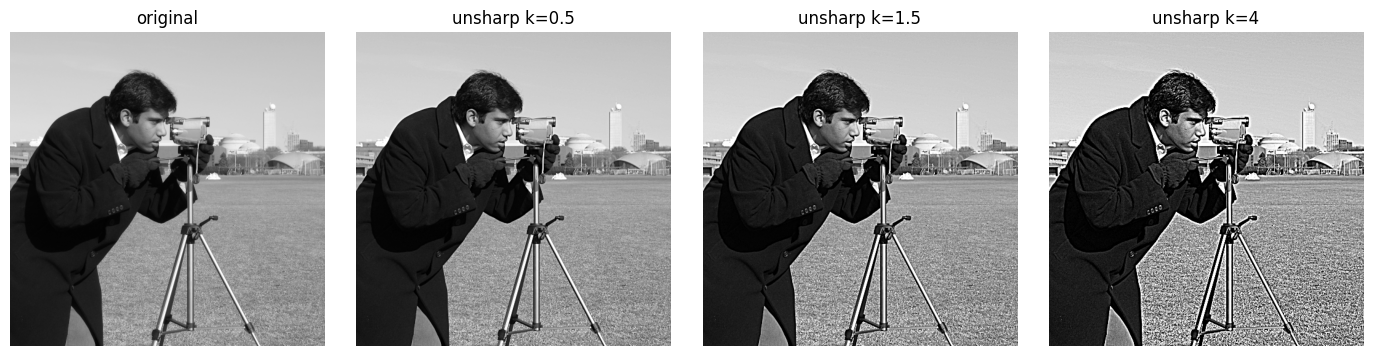

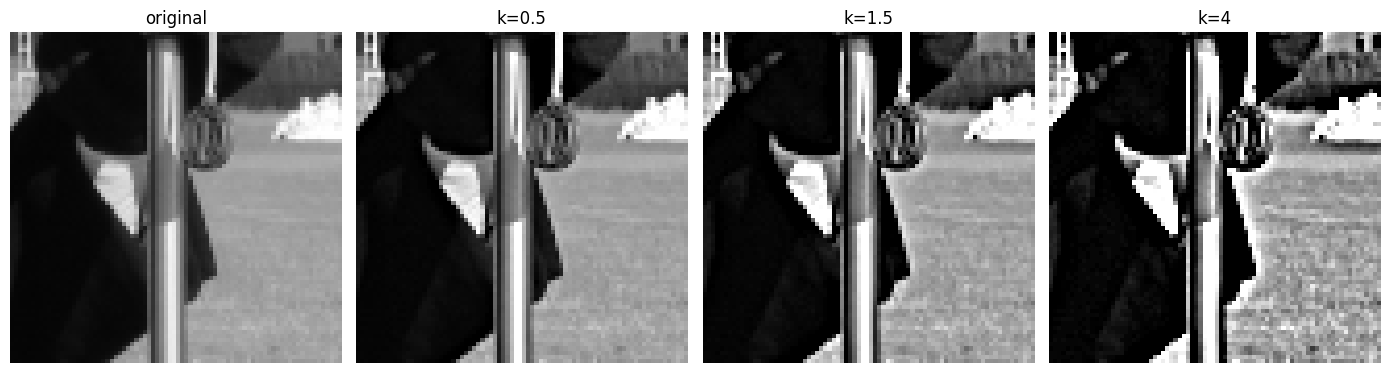

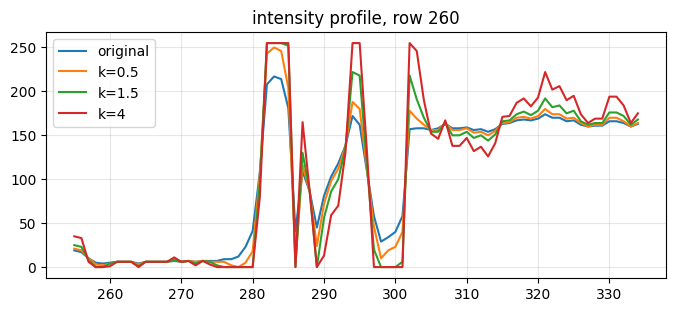

In [ ]:
ks_u = [0.5, 1.5, 4]
outs = {k_: cv2.addWeighted(I, 1 + k_, blur, -k_, 0) for k_ in ks_u}
show_row([I] + list(outs.values()), ["original"] + [f"unsharp k={k_}" for k_ in ks_u], size=3.5)

y0, y1, x0, x1 = 215, 295, 255, 335      
crops = [I[y0:y1, x0:x1]] + [o[y0:y1, x0:x1] for o in outs.values()]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for a, c, t in zip(axes, crops, ["original"] + [f"k={k_}" for k_ in ks_u]):
    a.imshow(c, cmap="gray", vmin=0, vmax=255, interpolation="nearest"); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()

row = 260
plt.figure(figsize=(8, 3.2))
for lab, img in [("original", I)] + [(f"k={k_}", o) for k_, o in outs.items()]:
    plt.plot(range(x0, x1), img[row, x0:x1], label=lab)
plt.title(f"intensity profile, row {row}"); plt.legend(); plt.grid(alpha=.3); plt.show()

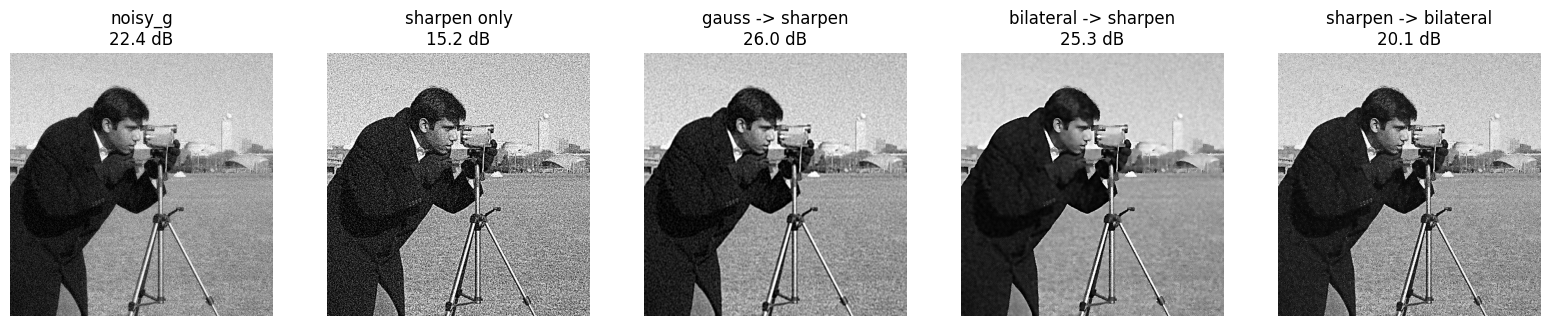

noisy_g                 22.42
sharpen only            15.19
gauss -> sharpen        25.95
bilateral -> sharpen    25.29
sharpen -> bilateral    20.15
Name: PSNR (dB), dtype: float64


In [ ]:
def unsharp_f(img, k=1.5, s=2):
    return cv2.addWeighted(img, 1 + k, cv2.GaussianBlur(img, (0, 0), s), -k, 0)

direct   = unsharp_f(noisy_g, 1.5, 2)                                  
den_first = unsharp_f(cv2.bilateralFilter(noisy_g, 9, 50, 9), 1.5, 2)   
den_first2 = unsharp_f(cv2.GaussianBlur(noisy_g, (5, 5), 1.2), 1.5, 2)
sharp_first = cv2.bilateralFilter(unsharp_f(noisy_g, 1.5, 2), 9, 50, 9) 

imgs = {"noisy_g": noisy_g, "sharpen only": direct, "gauss -> sharpen": den_first2,
        "bilateral -> sharpen": den_first, "sharpen -> bilateral": sharp_first}
show_row(list(imgs.values()), [f"{k}\n{psnr(I, v):.1f} dB" for k, v in imgs.items()], size=3.2)
print(pd.Series({k: round(psnr(I, v), 2) for k, v in imgs.items()}, name="PSNR (dB)"))

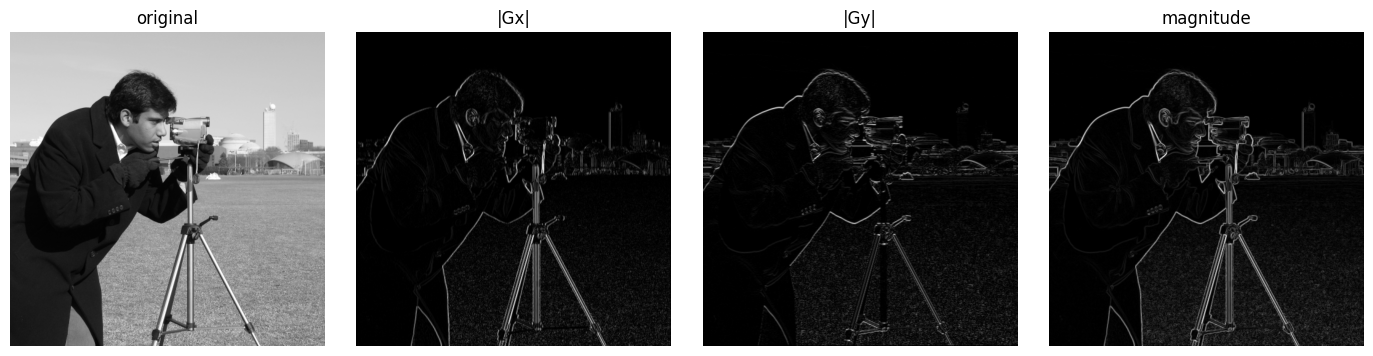

In [ ]:
gx = cv2.Sobel(I, cv2.CV_64F, 1, 0, ksize=3)    
gy = cv2.Sobel(I, cv2.CV_64F, 0, 1, ksize=3)   
mag = np.hypot(gx, gy)

def to_u8(x):
    """Scale any float array to 0..255 for display."""
    x = np.abs(x)
    return (255 * x / x.max()).astype(np.uint8)

show_row([I, to_u8(gx), to_u8(gy), to_u8(mag)],
         ["original", "|Gx|", "|Gy|", "magnitude"], size=3.5)

CV_8U : min = 0  negative pixels = 0
CV_64F: min = -860.0  negative pixels = 118800 (45.3% of the image)
CV_8U  zero pixels: 141251 (53.9%)   CV_64F zero pixels: 22451


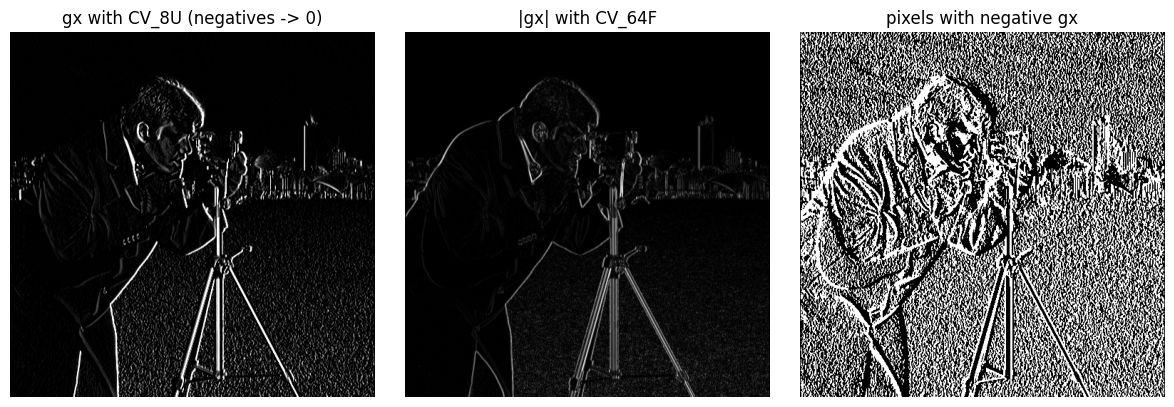

In [14]:
gx8  = cv2.Sobel(I, cv2.CV_8U,  1, 0, ksize=3)
gx64 = cv2.Sobel(I, cv2.CV_64F, 1, 0, ksize=3)

print("CV_8U : min =", gx8.min(), " negative pixels =", int((gx8 < 0).sum()))
print("CV_64F: min =", gx64.min(), " negative pixels =", int((gx64 < 0).sum()),
      f"({100 * (gx64 < 0).mean():.1f}% of the image)")
print("CV_8U  zero pixels:", int((gx8 == 0).sum()), f"({100*(gx8==0).mean():.1f}%)   CV_64F zero pixels:", int((gx64 == 0).sum()))

neg_mask = (gx64 < 0)
show_row([gx8, to_u8(gx64), neg_mask.astype(np.uint8) * 255],
         ["gx with CV_8U (negatives -> 0)", "|gx| with CV_64F", "pixels with negative gx"], size=4)

80th percentile -> T = 73.4, edge pixels = 20.0%
90th percentile -> T = 124.4, edge pixels = 10.0%
95th percentile -> T = 201.1, edge pixels = 5.0%


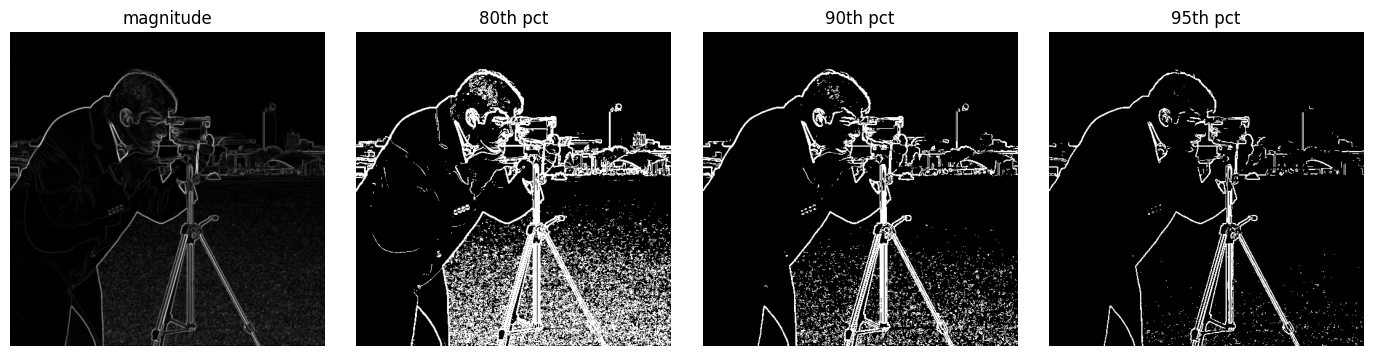

In [15]:
ps = [80, 90, 95]
edge_maps = []
for p in ps:
    t = np.percentile(mag, p)
    edge_maps.append((mag > t).astype(np.uint8) * 255)
    print(f"{p}th percentile -> T = {t:.1f}, edge pixels = {100 * (mag > t).mean():.1f}%")
show_row([to_u8(mag)] + edge_maps, ["magnitude"] + [f"{p}th pct" for p in ps], size=3.5)

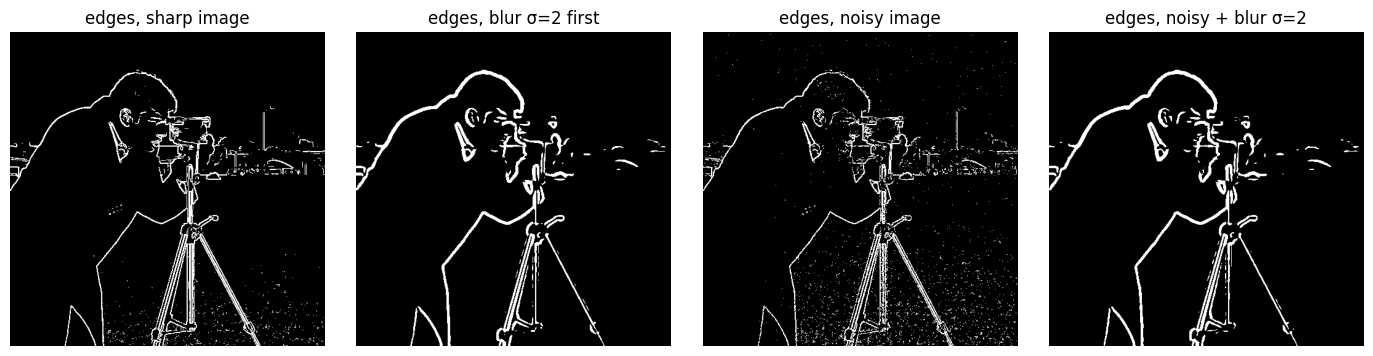

max gradient magnitude: sharp 930.0  blurred 334.0


In [ ]:
Ib = cv2.GaussianBlur(I, (0, 0), 2)
gxb = cv2.Sobel(Ib, cv2.CV_64F, 1, 0, ksize=3)
gyb = cv2.Sobel(Ib, cv2.CV_64F, 0, 1, ksize=3)
magb = np.hypot(gxb, gyb)
t95  = np.percentile(mag, 95);  t95b = np.percentile(magb, 95)
em, emb = mag > t95, magb > t95b

mag_n  = np.hypot(cv2.Sobel(noisy_g, cv2.CV_64F, 1, 0), cv2.Sobel(noisy_g, cv2.CV_64F, 0, 1))
nb_    = cv2.GaussianBlur(noisy_g, (0, 0), 2)
mag_nb = np.hypot(cv2.Sobel(nb_, cv2.CV_64F, 1, 0), cv2.Sobel(nb_, cv2.CV_64F, 0, 1))

show_row([em * 255, emb * 255, (mag_n > np.percentile(mag_n, 95)) * 255, (mag_nb > np.percentile(mag_nb, 95)) * 255],
         ["edges, sharp image", "edges, blur σ=2 first", "edges, noisy image", "edges, noisy + blur σ=2"], size=3.5)
print("max gradient magnitude: sharp", mag.max().round(0), " blurred", magb.max().round(0))

Damaged PSNR: 12.62 dB


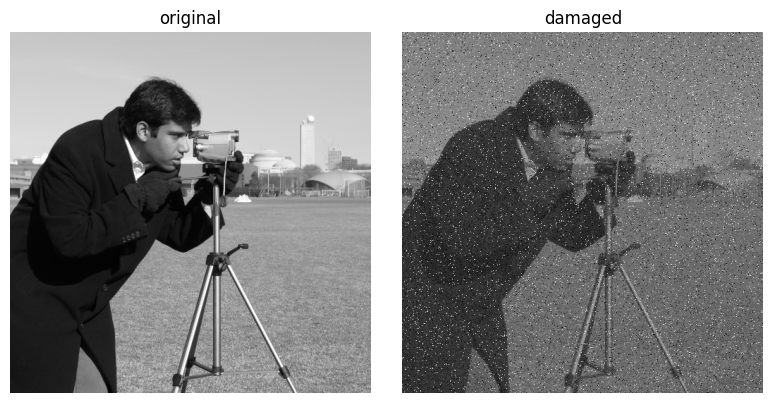

In [ ]:
rng = np.random.default_rng(2026)
damaged = point_op(I, 0.45, 40).astype(np.float64)    
damaged += rng.normal(0, 12, I.shape)               
r = rng.random(I.shape)
damaged[r < 0.02] = 0;  damaged[r > 0.98] = 255      
damaged = np.clip(damaged, 0, 255).astype(np.uint8)

print(f"Damaged PSNR: {psnr(I, damaged):.2f} dB")   
show_row([I, damaged], ["original", "damaged"])

In [ ]:
def minmax_stretch(x):
    x = x.astype(np.float64); lo, hi = x.min(), x.max()
    return np.clip((x - lo) / (hi - lo) * 255, 0, 255).astype(np.uint8)

def pct_stretch(x, plo=0.5, phi=99.5):
    x = x.astype(np.float64); lo, hi = np.percentile(x, [plo, phi])
    return np.clip((x - lo) / (hi - lo) * 255, 0, 255).astype(np.uint8)

print("damaged  min/max:", damaged.min(), damaged.max(), "  (dead pixels pin them to 0 and 255)")
med = cv2.medianBlur(damaged, 3)
print("median3  min/max:", med.min(), med.max())

trials = {
 "damaged":                             damaged,
 "min-max stretch only":                minmax_stretch(damaged),
 "stretch -> median (wrong order)":     cv2.medianBlur(pct_stretch(damaged), 3),
 "median -> min-max stretch":           minmax_stretch(med),
 "median -> pct stretch":               pct_stretch(med),
 "median -> gauss -> pct stretch":      pct_stretch(cv2.GaussianBlur(med, (5, 5), 1.0)),
 "median -> bilateral -> pct stretch":  pct_stretch(cv2.bilateralFilter(med, 7, 20, 3)),
 "median -> bilateral -> stretch -> sharpen": unsharp_f(pct_stretch(cv2.bilateralFilter(med, 7, 20, 3)), 0.5, 1.5),
}
print(pd.Series({k: round(psnr(I, v), 2) for k, v in trials.items()}, name="PSNR (dB)").to_string())

damaged  min/max: 0 255   (dead pixels pin them to 0 and 255)
median3  min/max: 0 165
damaged                                      12.62
min-max stretch only                         12.62
stretch -> median (wrong order)              13.74
median -> min-max stretch                    17.87
median -> pct stretch                        23.12
median -> gauss -> pct stretch               22.83
median -> bilateral -> pct stretch           23.32
median -> bilateral -> stretch -> sharpen    23.16


damaged  PSNR: 12.62 dB
rescued  PSNR: 23.32 dB   (goal >= 22 dB: PASS; gain = +10.70 dB)


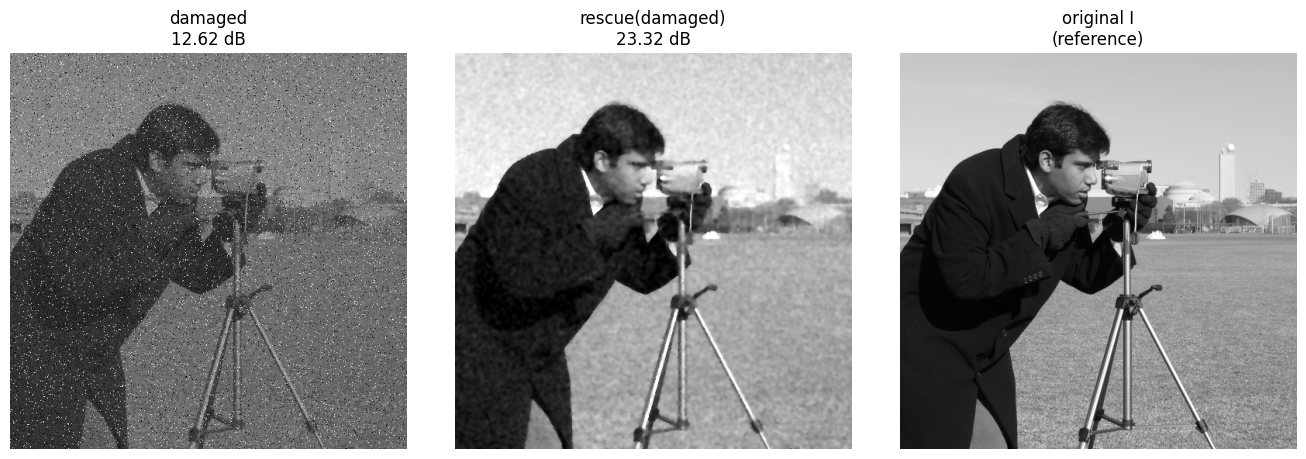

In [ ]:
def rescue(img):
    """Restore a low-contrast, noisy photo with dead/hot pixels.
    Order: 1) median  2) bilateral  3) percentile contrast stretch."""
  
    out = cv2.medianBlur(img, 3)
   
    out = cv2.bilateralFilter(out, 7, 20, 3)
    
    lo, hi = np.percentile(out, [0.5, 99.5])
    out = np.clip((out.astype(np.float64) - lo) / (hi - lo) * 255, 0, 255)
    return out.astype(np.uint8)

restored = rescue(damaged)
p_dmg, p_res = psnr(I, damaged), psnr(I, restored)
print(f"damaged  PSNR: {p_dmg:.2f} dB")
print(f"rescued  PSNR: {p_res:.2f} dB   (goal >= 22 dB: {'PASS' if p_res >= 22 else 'FAIL'}; gain = {p_res - p_dmg:+.2f} dB)")
show_row([damaged, restored, I],
         [f"damaged\n{p_dmg:.2f} dB", f"rescue(damaged)\n{p_res:.2f} dB", "original I\n(reference)"], size=4.5)

In [ ]:
# Bonus 
for kk in (0.0, 0.3, 0.6, 1.0):
    s = unsharp_f(restored, kk, 1.5) if kk else restored
    print(f"unsharp k={kk}: {psnr(I, s):.2f} dB")

unsharp k=0.0: 23.32 dB
unsharp k=0.3: 23.25 dB
unsharp k=0.6: 23.11 dB
unsharp k=1.0: 22.82 dB
